# 8. Eigenvalue problems and pseudospectra

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/08_eigenvalue_problems.ipynb)

*Companion to Chapter 9 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Natural frequencies, buckling loads, decay rates and energy levels are all eigenvalues of
differential operators. Replace the derivatives by the matrices of notebook 5 and the
differential eigenvalue problem becomes a matrix eigenvalue problem that one library call
solves. The work is in knowing which of the computed numbers to believe.

- how many eigenvalues of a spectral matrix are accurate, and how to tell without an exact answer
- variable coefficients and singular end points, as a generalized eigenvalue problem
- an unbounded domain, cut off at a finite length
- two dimensions with the Kronecker products of notebook 6
- operators whose eigenvalues are extremely sensitive, and the pseudospectra that describe them

**Worked examples:** the swinging modes of a hanging chain, the quantum harmonic oscillator,
the modes of a square membrane, and a convection-diffusion operator whose eigenvalues mislead.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct                 # discrete cosine transform, used only inside clenshaw_curtis (notebooks 7 and 10)
from scipy.linalg import eig, expm
from scipy.special import j0, jn_zeros

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))
    D -= np.diag(D.sum(axis=1))
    return D, x

# barycentric_interpolate(values, x_eval) from notebook 4: evaluates the interpolant between the grid points
def barycentric_interpolate(values, x_eval):
    """Evaluate the polynomial interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    w = (-1.0) ** j
    w[0] /= 2
    w[N] /= 2
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - x[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    ratio = w / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

# clenshaw_curtis(N), as pasted in notebook 6: weights w_j with ∫ f dx ≈ Σ w_j f(x_j) on the Chebyshev points; derived in notebook 10
def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)
    w = dct(moments, type=1) / N
    w[0] /= 2
    w[N] /= 2
    return x, w

## 8.1 The model problem: which eigenvalues can be trusted?

**Problem.** Find the numbers $\lambda$ for which

$$u'' = \lambda u,\qquad u(-1) = u(1) = 0$$

has a solution other than $u = 0$. This is the taut string, the pinned column and the cooling
slab in one: $\sqrt{-\lambda}$ is a natural frequency or a buckling parameter, $-\lambda$ a
decay rate.

**By hand.** The solutions that vanish at $x = -1$ are $\sin\big(\mu(x+1)\big)$ with
$\lambda = -\mu^2$. They vanish at $x = 1$ when $2\mu = k\pi$, so

$$\lambda_k = -\Big(\frac{k\pi}{2}\Big)^2,\qquad u_k(x) = \sin\frac{k\pi(x+1)}{2},\qquad k = 1, 2, 3, \dots$$

On the Chebyshev grid the unknowns are the interior values $u_1, \dots, u_{N-1}$ (index 0 is
$x = +1$ and index $N$ is $x = -1$, where $u$ is zero). As in notebook 6, the boundary
conditions are imposed by deleting the first and last rows and columns of $D^2$. The
eigenvalues of the remaining $(N-1)\times(N-1)$ matrix approximate $\lambda_1, \lambda_2, \dots$

In [3]:
def dirichlet_d2(N):
    """Second-derivative matrix acting on the interior values, for u(±1) = 0, and the interior points."""
    D, x = cheb(N)
    return (D @ D)[1:-1, 1:-1], x[1:-1]

N = 36
computed = np.sort(np.linalg.eigvals(dirichlet_d2(N)[0]).real)[::-1]       # from the smallest |λ| upwards
k = np.arange(1, N)
exact = -(k * np.pi / 2) ** 2
relative_error = np.abs(computed - exact) / np.abs(exact)

print("  k      computed         exact     relative error")
for i in (0, 1, 2, 9, 14, 17, 20, 23, 29, 34):
    print(f"{k[i]:3d} {computed[i]:14.6f} {exact[i]:13.6f} {relative_error[i]:12.1e}")

  k      computed         exact     relative error
  1      -2.467401     -2.467401      1.2e-14
  2      -9.869604     -9.869604      3.6e-15
  3     -22.206610    -22.206610      4.3e-15
 10    -246.740110   -246.740110      2.3e-13
 15    -555.165267   -555.165248      3.6e-08
 18    -799.455701   -799.437956      2.2e-05
 21   -1081.384386  -1088.123885      6.2e-03
 24   -1548.226626  -1421.223034      8.9e-02
 30   -5860.910264  -2220.660990      1.6e+00
 35  -79900.127044  -3022.566348      2.5e+01


A matrix of size 35 has 35 eigenvalues, and the differential operator has infinitely many.
The first ones are correct to rounding error. The last ones are wrong by factors of ten or
more: the largest is close to $-0.048N^4$ and has nothing to do with $\lambda_{35}$. They are
artefacts of the grid, and notebook 9 shows that they are the ones that limit the time step.

N = 36: 2N/π = 22.9
   the first 14 eigenvalues have relative error below 1e-08
   the first 18 eigenvalues have relative error below 1e-04
   the first 21 eigenvalues have relative error below 1e-02


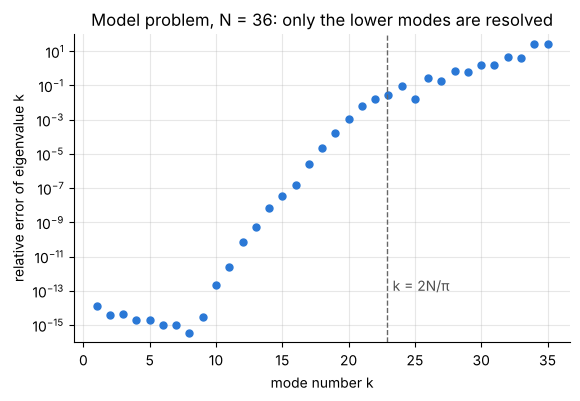

In [4]:
limit = 2 * N / np.pi
accurate = {tol: int(np.argmax(relative_error > tol)) for tol in (1e-8, 1e-4, 1e-2)}   # leading eigenvalues below tol
print(f"N = {N}: 2N/π = {limit:.1f}")
for tol, count in accurate.items():
    print(f"   the first {count} eigenvalues have relative error below {tol:.0e}")

fig, ax = plt.subplots()
ax.semilogy(k, relative_error, "o", ms=5)
ax.axvline(limit, color="0.4", ls="--", lw=1)
ax.annotate("k = 2N/π", xy=(limit + 0.4, 1e-13), color="0.3")
ax.set(xlabel="mode number k", ylabel="relative error of eigenvalue k", ylim=(1e-16, 1e2),
       title=f"Model problem, N = {N}: only the lower modes are resolved");

**The rule.** Mode $k$ has $k/2$ wavelengths in the interval, so $N$ grid points give it
$2N/k$ points per wavelength on average. A Fourier grid needs 2 points per wavelength. The
Chebyshev grid is $\pi/2$ times coarser than average at the centre of the interval, where the
spacing is $\pi/N$, so it needs $\pi$ **points per wavelength** on average: $2N/k \ge \pi$,
or

$$k \le \frac{2N}{\pi} \approx 0.64\,N .$$

The limit is approximate, not sharp. Modes well beyond it cannot be represented on the grid at
all, and modes just below it are represented but poorly. The measured counts show how the limit
is approached.

In [5]:
# Verify: about 2N/π eigenvalues are meaningful, those well beyond that limit are not, and about half are accurate
assert np.abs(computed[:9] - exact[:9]).max() < 1e-10
assert abs(accurate[1e-2] - limit) < 3 and relative_error[k > 1.2 * limit].min() > 0.1
assert accurate[1e-4] >= N // 2 and accurate[1e-8] >= 14

With $N = 36$ the limit is 22.9. Measured: 21 eigenvalues are within 1 per cent, 18 (half of
$N$) have four correct digits and 14 have eight. So $2N/\pi$ marks, approximately, the edge of
the usable range. It is not a count of accurate eigenvalues. A safe working figure is that the lowest $N/2$
eigenvalues are good to several digits, and the lowest $N/3$ to many.

**What to do without an exact answer.** Compute twice, with $N$ and with a larger $N$, and
keep the eigenvalues that do not move.

In [6]:
def settled_eigenvalues(N_coarse, N_fine, tol=1e-6):
    """Number of leading eigenvalues of the model problem that agree between two grids to relative tol."""
    coarse = np.sort(np.linalg.eigvals(dirichlet_d2(N_coarse)[0]).real)[::-1]
    fine = np.sort(np.linalg.eigvals(dirichlet_d2(N_fine)[0]).real)[::-1][:len(coarse)]
    return int(np.argmax(np.abs(coarse - fine) > tol * np.abs(fine)))

n_settled = settled_eigenvalues(36, 48)
print(f"eigenvalues that agree between N = 36 and N = 48 to 6 digits: {n_settled}")
assert relative_error[:n_settled].max() < 2e-6 and n_settled >= 15      # the test keeps only eigenvalues that are right

eigenvalues that agree between N = 36 and N = 48 to 6 digits: 16


The two-grid test keeps 16 eigenvalues, and comparison with the exact values confirms that
every one of them is correct to six digits. This test is the habit to take away from this
notebook, and it is used again below.

## 8.2 Worked example: a hanging chain

**Problem.** A uniform chain of length $L$ hangs from a fixed support and swings sideways with
small amplitude. With $x$ measured upwards from the free end, the tension at height $x$ is the
weight of the chain below, $\rho g x$, and the sideways displacement $u(x)\,e^{i\omega t}$
satisfies

$$\frac{d}{dx}\Big(x\,\frac{du}{dx}\Big) + \frac{\omega^2}{g}\,u = 0,\qquad u(L) = 0,\qquad u \text{ bounded at } x = 0 .$$

Find the first three natural frequencies of a chain with $L = 1.5$ m.

**By hand.** The substitution $s = 2\omega\sqrt{x/g}$ turns the equation into Bessel's equation
of order zero, so the bounded solution is $u = J_0\big(2\omega\sqrt{x/g}\big)$. The condition
at the support gives

$$\omega_k = \frac{j_{0,k}}{2}\sqrt{\frac{g}{L}},\qquad j_{0,k} = 2.404826,\ 5.520078,\ 8.653728,\ \dots \text{ (the zeros of } J_0).$$

Two things are new for the numerical method.

- **A variable coefficient.** Expanding the derivative, the operator is $x\,u'' + u'$. On the
  grid, multiplication by $x$ is a diagonal matrix: $A = \mathrm{diag}(x)\,D^2 + D$.
- **A singular end point.** At $x = 0$ the coefficient of $u''$ vanishes and the equation
  itself reduces to $u'(0) + (\omega^2/g)\,u(0) = 0$. The differential equation supplies its own
  condition there, and the polynomial interpolant is automatically bounded. So **no row is
  replaced at the free end**: the row of $A$ for that point is kept as it is.

At the support the row is replaced by the condition $u(L) = 0$. That row contains no
eigenvalue, so the problem takes the generalized form

$$-A\,\mathbf{u} = \frac{\omega^2}{g}\,B\,\mathbf{u},$$

where $B$ is the identity with the row of the support set to zero. Because $B$ is singular,
one of the $N+1$ eigenvalues is infinite. `scipy.linalg.eig(A, B)` reports it as `inf` and it is
discarded.

In [7]:
g, L_chain = 9.81, 1.5                                   # m/s², m

def chain_modes(N):
    """Frequencies (rad/s) and mode shapes of the hanging chain; index 0 is the support x = L, index N the free end."""
    D, xi = cheb(N)
    D, x = D * 2 / L_chain, L_chain * (xi + 1) / 2       # map [-1, 1] to [0, L], as scale_cheb does in notebook 5
    A = np.diag(x) @ D @ D + D
    B = np.eye(N + 1)
    A[0, :], A[0, 0], B[0, 0] = 0.0, 1.0, 0.0            # row 0 (the support): u_0 = 0, no eigenvalue in this row
    values, vectors = eig(-A, B)
    keep = np.isfinite(values) & (np.abs(values.imag) < 1e-8) & (values.real > 0)
    order = np.argsort(values.real[keep])
    return np.sqrt(g * values.real[keep][order]), vectors.real[:, keep][:, order], x

omega, shapes, x = chain_modes(20)
omega_exact = jn_zeros(0, 3) / 2 * np.sqrt(g / L_chain)
print("mode   computed ω (rad/s)   exact ω (rad/s)   frequency (Hz)")
for i in range(3):
    print(f"{i + 1:3d} {omega[i]:18.10f} {omega_exact[i]:17.10f} {omega[i] / (2 * np.pi):13.4f}")

mode   computed ω (rad/s)   exact ω (rad/s)   frequency (Hz)
  1       3.0749811462      3.0749811462        0.4894
  2       7.0583648200      7.0583648200        1.1234
  3      11.0652725273     11.0652725273        1.7611


**Verify** against the zeros of $J_0$ (from `scipy.special`, an independent source), against the
exact mode shapes, and with the two-grid test.

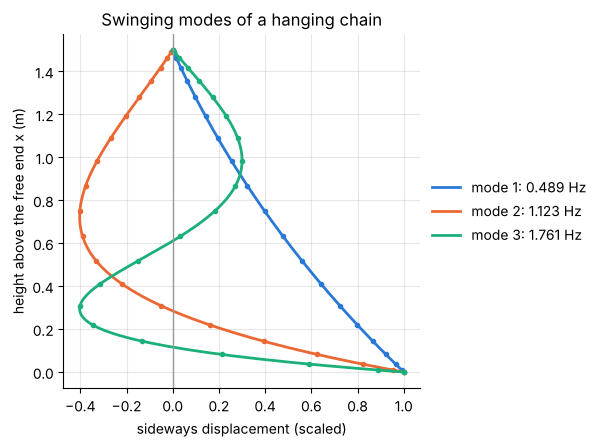

In [8]:
assert np.allclose(jn_zeros(0, 3), [2.404826, 5.520078, 8.653728], atol=5e-7)
assert np.abs(omega[:3] - omega_exact).max() < 1e-8
assert np.abs(chain_modes(28)[0][:3] - omega[:3]).max() < 1e-8                 # unchanged on a finer grid

xi_fine = np.linspace(-1, 1, 201)                                              # the interpolant between the grid points
fig, ax = plt.subplots(figsize=(4.6, 4.6))
for i in range(3):
    shape = shapes[:, i] / shapes[-1, i]                                       # scaled to 1 at the free end
    assert np.abs(shape - j0(2 * omega_exact[i] * np.sqrt(x / g))).max() < 1e-8
    line, = ax.plot(barycentric_interpolate(shape, xi_fine), L_chain * (xi_fine + 1) / 2, label=f"mode {i + 1}: {omega[i] / (2 * np.pi):.3f} Hz")
    ax.plot(shape, x, "o", ms=3, color=line.get_color())                       # the values at the 21 grid points
ax.axvline(0, color="0.6", lw=1)
ax.set(xlabel="sideways displacement (scaled)", ylabel="height above the free end x (m)",
       title="Swinging modes of a hanging chain")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

Twenty-one points give the three frequencies to better than $10^{-8}$ rad/s, with no special
treatment of the singular end. For comparison, a simple pendulum of the same length (a point
mass on a light string) swings at $\sqrt{g/L}/2\pi = 0.407$ Hz and a rigid rod pivoted at its
end at 0.498 Hz; the chain's
fundamental, 0.489 Hz, is close to the rod's. The motion is largest at the free end, where the
tension that provides the restoring force is smallest. Crane cables, mooring lines and towed
cables are modelled in the same way, with a tip mass or drag added.

## 8.3 Worked example: the harmonic oscillator on a truncated domain

**Problem.** The stationary states of a quantum particle in a parabolic potential satisfy, in
scaled units,

$$-u'' + x^2 u = \lambda u,\qquad u \to 0 \text{ as } x \to \pm\infty .$$

The exact eigenvalues are $\lambda = 1, 3, 5, \dots$, with eigenfunctions
$H_n(x)\,e^{-x^2/2}$ ($H_n$ a polynomial of degree $n$). The domain is the whole real line and
the Chebyshev grid is not. What is the simplest way out?

**By hand.** The eigenfunctions decay like $e^{-x^2/2}$: at $x = 8$ that factor is $10^{-14}$.
So cut the line off at $x = \pm L$, impose $u(\pm L) = 0$, and scale the grid to $[-L, L]$,
which divides $D$ by $L$. There are now two numerical parameters, and they pull in opposite
directions:

- $L$ must be large enough that the eigenfunctions wanted are negligible at $\pm L$;
- $N$ must be large enough to resolve them, and the same $N$ spread over a longer interval
  resolves less.

In [9]:
def oscillator_eigenvalues(N, L):
    """Eigenvalues of -u'' + x² u on [-L, L] with u(±L) = 0, in increasing order."""
    D2, xi = dirichlet_d2(N)
    H = -D2 / L**2 + np.diag((L * xi) ** 2)
    return np.sort(np.linalg.eigvals(H).real)

first_five = np.arange(1, 10, 2)
print("largest error in the first five eigenvalues")
print("   L      N = 24      N = 36      N = 48      N = 64")
table = {}
for L in (4, 6, 8, 10):
    table[L] = [np.abs(oscillator_eigenvalues(N, L)[:5] - first_five).max() for N in (24, 36, 48, 64)]
    print(f"{L:4d} " + "".join(f"{err:12.1e}" for err in table[L]))

largest error in the first five eigenvalues
   L      N = 24      N = 36      N = 48      N = 64
   4      1.9e-02     1.9e-02     1.9e-02     1.9e-02
   6      3.8e-02     1.7e-07     2.6e-09     2.6e-09
   8      6.5e-01     2.2e-03     4.8e-08     2.9e-14
  10      1.7e+00     1.7e-01     2.6e-04     5.5e-10


In [10]:
# Verify: L = 8, N = 64 gives the first five eigenvalues to 1e-8; the two failure modes are visible in the table
assert np.abs(oscillator_eigenvalues(64, 8)[:5] - first_five).max() < 1e-8
assert table[4][3] > 1e-3                      # L = 4: domain too short, more points do not help
assert table[10][0] > 1.0                      # L = 10, N = 24: domain long enough, grid too coarse

Read the table by rows and by columns. With $L = 4$ the error stays at 0.02 however large $N$
is: the fifth eigenfunction is not small at $x = 4$ and the wall at $\pm L$ squeezes it. With
$L = 10$ and $N = 24$ the domain is long enough but the grid is too coarse. $L = 8$ with
$N = 64$ gives all five eigenvalues to $10^{-13}$.

In practice: increase $L$ until the answer stops changing, then increase $N$ until it stops
changing, and check again. The same truncation works for any problem on an unbounded domain
whose solution decays quickly, for instance a bound state, a trapped wave or a boundary layer
profile.

## 8.4 Worked example: modes of a square membrane

**Problem.** A square membrane (a drum skin, a MEMS diaphragm) occupies $-1 \le x, y \le 1$ and
is fixed at the edge. Its modes satisfy $\nabla^2 u = \lambda u$ with $u = 0$ on the boundary,
and the natural frequencies are proportional to $\sqrt{-\lambda}$.

**By hand.** Products of the one-dimensional modes of 8.1 are solutions:

$$u_{mn} = \sin\frac{m\pi(x+1)}{2}\,\sin\frac{n\pi(y+1)}{2},\qquad
\lambda_{mn} = -\frac{\pi^2}{4}\,(m^2 + n^2),\qquad m, n = 1, 2, \dots$$

Whenever $m \ne n$ the modes $u_{mn}$ and $u_{nm}$ have the same eigenvalue. Such eigenvalues
are called **degenerate**, and they are a consequence of the symmetry of the square.

The matrix is the Laplacian of notebook 6, $L = I \otimes D^2 + D^2 \otimes I$, built from the
interior matrix of 8.1. A sum of Kronecker products of this form is called a Kronecker sum. It
has $(N-1)^2$ rows.

In [11]:
N = 24
D2, xi = dirichlet_d2(N)
I = np.eye(N - 1)
laplacian = np.kron(I, D2) + np.kron(D2, I)
values, vectors = np.linalg.eig(laplacian)
order = np.argsort(-values.real)
values, vectors = values.real[order], vectors.real[:, order]

pairs = sorted((m * m + n * n, m, n) for m in range(1, 8) for n in range(1, 8))[:10]
print("computed -λ/(π²/4)    exact m² + n²   (m, n)")
for value, (total, m, n) in zip(values[:10], pairs):
    print(f"{-value / (np.pi**2 / 4):16.10f} {total:12d}        ({m}, {n})")

computed -λ/(π²/4)    exact m² + n²   (m, n)
    2.0000000000            2        (1, 1)
    5.0000000000            5        (1, 2)
    5.0000000000            5        (2, 1)
    8.0000000000            8        (2, 2)
   10.0000000000           10        (1, 3)
   10.0000000000           10        (3, 1)
   13.0000000000           13        (2, 3)
   13.0000000000           13        (3, 2)
   17.0000000000           17        (1, 4)
   17.0000000000           17        (4, 1)


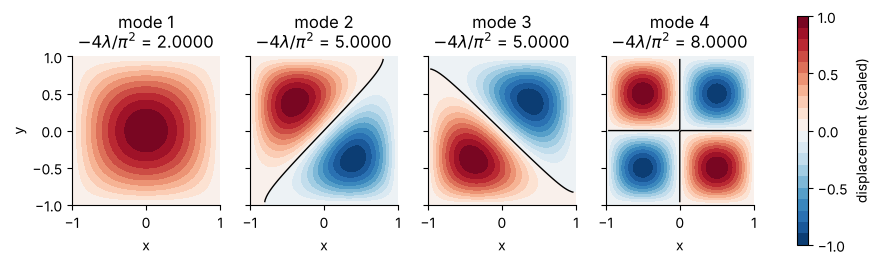

In [12]:
# Verify: the first ten eigenvalues, including the four degenerate pairs among them
assert np.abs(-values[:10] / (np.pi**2 / 4) - [p[0] for p in pairs]).max() < 1e-9
assert all(abs(values[i] - values[i + 1]) < 1e-9 for i in (1, 4, 6, 8))

# for plotting, evaluate the interpolant on a fine uniform grid: P maps grid values to values at x_fine
x_fine = np.linspace(-1, 1, 121)
P = np.array([barycentric_interpolate(column, x_fine) for column in np.eye(N + 1)]).T

fig, axes = plt.subplots(1, 4, figsize=(11, 3.3), sharey=True)
for ax, i in zip(axes, range(4)):
    mode = np.zeros((N + 1, N + 1))
    mode[1:-1, 1:-1] = vectors[:, i].reshape(N - 1, N - 1)
    mode = P @ mode @ P.T
    mode /= mode.flat[np.abs(mode).argmax()]                      # scale so that the largest value is +1
    image = ax.contourf(x_fine, x_fine, mode, levels=np.linspace(-1, 1, 21), cmap="RdBu_r")
    ax.contour(x_fine[2:-2], x_fine[2:-2], mode[2:-2, 2:-2], levels=[0], colors="k", linewidths=1)
    ax.set(title=f"mode {i + 1}\n$-4\\lambda/\\pi^2$ = {-values[i] / (np.pi**2 / 4):.4f}", xlabel="x", aspect="equal")
    ax.grid(False)
axes[0].set_ylabel("y")
fig.colorbar(image, ax=axes, label="displacement (scaled)", ticks=[-1, -0.5, 0, 0.5, 1], shrink=0.9);

The black lines are the nodal lines, where the membrane does not move. Modes 2 and 3 share the
eigenvalue 5. Any combination of two modes with the same eigenvalue is again a mode, so the
eigenvalue routine is free to return any two independent combinations of $u_{12}$ and
$u_{21}$, and the nodal line it shows need not be parallel to an edge. Which combination is
seen in an experiment is decided by small imperfections or by how the membrane is driven.

For the designer the degenerate pairs matter for another reason: a small asymmetry (a slightly
rectangular plate, an added mass) splits each pair into two close frequencies, which is heard
as beating.

## 8.5 A non-normal operator: convection and diffusion

All the operators so far were self-adjoint, the counterpart for differential operators of a
symmetric matrix: their eigenfunctions are orthogonal, and their eigenvalues tell the whole
story. The next one is not.

**Problem.** A scalar (heat, a solute) is carried to the left at unit speed and diffuses with a
small diffusivity $\nu$ between two walls where it is held at zero:

$$u_t = \mathcal{L}u,\qquad \mathcal{L}u = \nu\,u'' + u',\qquad u(-1) = u(1) = 0 .$$

What are the eigenvalues of $\mathcal{L}$, and what do they say about how fast $u$ decays?

**By hand.** Substitute $u = e^{-x/(2\nu)}\,v$. The first-derivative term cancels and
$\mathcal{L}u = e^{-x/(2\nu)}\big(\nu v'' - \tfrac{1}{4\nu}v\big)$, a symmetric operator acting
on $v$. With 8.1 this gives

$$\lambda_k = -\frac{1}{4\nu} - \nu\Big(\frac{k\pi}{2}\Big)^2,\qquad
u_k(x) = e^{-x/(2\nu)}\,\sin\frac{k\pi(x+1)}{2} .$$

The eigenvalues are real and negative. For $\nu = 0.02$ the first is $-12.55$, which suggests
decay like $e^{-12.55t}$. But look at the eigenfunctions: the factor $e^{-x/(2\nu)}$ varies by
$e^{50} \approx 5\times10^{21}$ across the interval, so every $u_k$ is a thin spike at the left wall,
and they all look alike. The eigenfunctions are far from orthogonal. An operator like this is
called **non-normal**.

In [13]:
def convection_diffusion(N, nu):
    """Matrix of ν u'' + u' with u(±1) = 0, acting on the interior values, and the interior points."""
    D, x = cheb(N)
    return (nu * D @ D + D)[1:-1, 1:-1], x[1:-1]

def exact_cd_eigenvalues(nu, count):
    return -1 / (4 * nu) - nu * (np.arange(1, count + 1) * np.pi / 2) ** 2

def rightmost(matrix, count):
    values = np.linalg.eigvals(matrix)
    return values[np.argsort(-values.real)][:count]

print("   ν     N    largest error in the real parts of the first five computed eigenvalues")
cd_error = {}
for nu, N in ((0.2, 40), (0.1, 40), (0.05, 40), (0.05, 80), (0.02, 40), (0.02, 80), (0.02, 120)):
    cd_error[nu, N] = np.abs(np.sort(rightmost(convection_diffusion(N, nu)[0], 5).real)[::-1]
                             - exact_cd_eigenvalues(nu, 5)).max()
    print(f"{nu:5.2f} {N:5d} {cd_error[nu, N]:12.1e}")

   ν     N    largest error in the real parts of the first five computed eigenvalues
 0.20    40      3.0e-13
 0.10    40      2.3e-12
 0.05    40      2.5e-08
 0.05    80      6.2e-08
 0.02    40      3.3e+00
 0.02    80      1.3e+00
 0.02   120      1.4e+00


In [14]:
# Verify the eigenvalue formula where the computation is reliable, and that it is not reliable for ν = 0.02
assert cd_error[0.2, 40] < 1e-10 and cd_error[0.1, 40] < 1e-9 and cd_error[0.05, 40] < 1e-4
assert min(cd_error[0.02, 40], cd_error[0.02, 80], cd_error[0.02, 120]) > 0.5

For $\nu = 0.2$ and $0.1$ the formula is reproduced to $10^{-11}$. For $\nu = 0.05$ about eight
digits survive, and more points do not improve them. For $\nu = 0.02$ the computed eigenvalues
are wrong in the first or second digit at every resolution, and most of them are complex where
the exact ones are real. The two-grid test would have raised the alarm: the numbers keep moving.

The discretization is not at fault. The exact eigenfunction, sampled on the grid, satisfies the
matrix equation almost perfectly:

In [15]:
nu = 0.02
A_cd, x_in = convection_diffusion(60, nu)
weights = clenshaw_curtis(60)[1][1:-1]                    # quadrature weights of the interior points
norm = lambda v: np.sqrt(weights @ np.abs(v) ** 2)        # discrete version of (∫ |v|² dx)^(1/2)

print("  k   exact λ_k    ‖(A − λ_k) u_k‖ / ‖u_k‖")
for mode in (1, 2, 3):
    lam = exact_cd_eigenvalues(nu, mode)[-1]
    u_exact = np.exp(-(x_in + 1) / (2 * nu)) * np.sin(mode * np.pi * (x_in + 1) / 2)
    residual = norm(A_cd @ u_exact - lam * u_exact) / norm(u_exact)
    print(f"{mode:3d} {lam:11.4f} {residual:16.1e}")
    assert residual < 1e-10

u1, u2 = (np.exp(-(x_in + 1) / (2 * nu)) * np.sin(m * np.pi * (x_in + 1) / 2) for m in (1, 2))
cosine = (weights @ (u1 * u2)) / (norm(u1) * norm(u2))
print(f"angle between the first two eigenfunctions: {np.degrees(np.arccos(cosine)):.2f} degrees (cosine {cosine:.6f})")
assert cosine > 0.99

  k   exact λ_k    ‖(A − λ_k) u_k‖ / ‖u_k‖
  1    -12.5493          1.2e-12
  2    -12.6974          1.3e-12
  3    -12.9441          1.3e-12
angle between the first two eigenfunctions: 0.41 degrees (cosine 0.999974)


So the exact eigenvalues and eigenfunctions satisfy the matrix equation with a relative residual
of $10^{-12}$, and still the eigenvalue routine does not return them. The reason is sensitivity. The first two eigenfunctions
point in almost the same direction (the angle between them is 0.4 degrees, where orthogonal
functions would give 90), and when eigenvectors are nearly parallel a tiny change in the
matrix moves the eigenvalues a long way. Rounding errors of relative size $10^{-16}$ are
enough. The next figure shows the computed spectra, and what a deliberate random perturbation
of the matrix does, of size $10^{-6}$ in the ordinary matrix 2-norm.

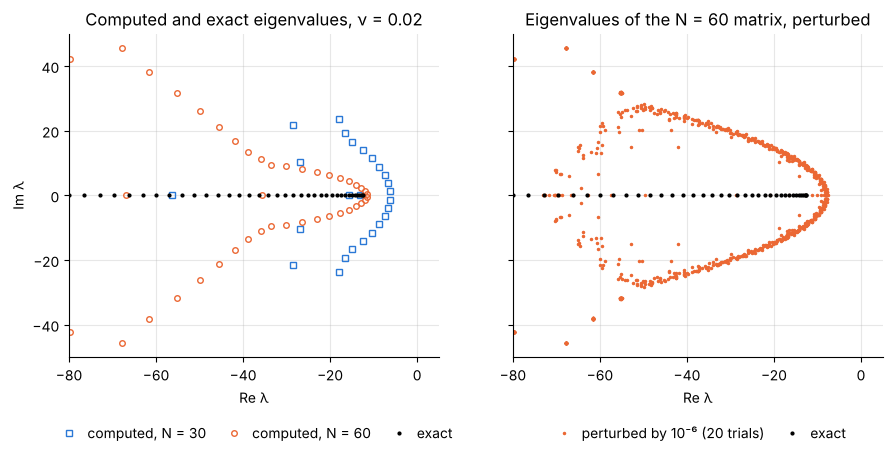

In [16]:
rng = np.random.default_rng(0)
exact_cd = exact_cd_eigenvalues(nu, 60)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for N, marker in ((30, "s"), (60, "o")):
    values = np.linalg.eigvals(convection_diffusion(N, nu)[0])
    axes[0].plot(values.real, values.imag, marker, ms=4, mfc="none", label=f"computed, N = {N}")
axes[0].plot(exact_cd, 0 * exact_cd, "k.", ms=4, label="exact")
axes[0].set(title="Computed and exact eigenvalues, ν = 0.02", xlabel="Re λ", ylabel="Im λ")
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, columnspacing=1.0, handletextpad=0.3)

shift_cd = []
for trial in range(20):
    E = rng.standard_normal(A_cd.shape)
    E *= 1e-6 / np.linalg.norm(E, 2)                              # a perturbation of 2-norm 1e-6
    perturbed = np.linalg.eigvals(A_cd + E)
    shift_cd.append(abs(perturbed.real.max() - exact_cd[0]))
    axes[1].plot(perturbed.real, perturbed.imag, ".", color="#eb6834", ms=3, label="perturbed by 10⁻⁶ (20 trials)" if trial == 0 else None)
axes[1].plot(exact_cd, 0 * exact_cd, "k.", ms=4, label="exact")
axes[1].set(title="Eigenvalues of the N = 60 matrix, perturbed", xlabel="Re λ")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, columnspacing=1.0, handletextpad=0.3)
for ax in axes:
    ax.set(xlim=(-80, 5), ylim=(-50, 50));

In [17]:
# Verify the contrast: the same perturbation applied to the symmetric operator u'' moves its eigenvalues by about 1e-6
D2_60 = dirichlet_d2(60)[0]
E = rng.standard_normal(D2_60.shape)
E *= 1e-6 / np.linalg.norm(E, 2)
shift_symmetric = np.abs(np.sort(np.linalg.eigvals(D2_60 + E).real)[::-1][:10] + (np.arange(1, 11) * np.pi / 2) ** 2).max()
print(f"shift of the leading eigenvalue under a perturbation of norm 1e-6:  u'': {shift_symmetric:.1e}   ν u'' + u': {min(shift_cd):.2f} or more")
assert shift_symmetric < 1e-5 and min(shift_cd) > 1.0

shift of the leading eigenvalue under a perturbation of norm 1e-6:  u'': 1.3e-07   ν u'' + u': 3.43 or more


The exact eigenvalues lie on the negative real axis (black). The computed ones leave it and
follow a curve that depends on $N$, and a perturbation in the sixth decimal place moves the
leading eigenvalue by more than three units, a million times the size of the perturbation. For the
symmetric operator $u''$ the same perturbation moves the eigenvalues by at most about
$10^{-6}$ (here $1.3\times10^{-7}$), as it should.

An eigenvalue that moves this easily cannot be measured, and a model is never known to six
digits. Something more robust than the spectrum is needed.

## 8.6 Pseudospectra

Ask a more forgiving question. Instead of "for which $z$ is $zI - A$ singular?", ask "for which
$z$ is $zI - A$ **nearly** singular?". The $\varepsilon$-**pseudospectrum** of $A$ is the set
of complex numbers $z$ with

$$\sigma_{\min}(zI - A) < \varepsilon ,$$

where $\sigma_{\min}$ is the smallest singular value. Two equivalent descriptions make the
meaning clear:

- $z$ is an eigenvalue of $A + E$ for some perturbation with $\|E\| < \varepsilon$;
- there is a vector $\mathbf{u}$ with $\|A\mathbf{u} - z\mathbf{u}\| < \varepsilon\|\mathbf{u}\|$,
  an "almost eigenvector".

For a symmetric (more generally, normal) matrix the $\varepsilon$-pseudospectrum is the set of
disks of radius $\varepsilon$ around the eigenvalues. For a non-normal matrix it can be far
larger.

**Which norm.** Singular values measure vectors by the sum of squares of their entries. On a
Chebyshev grid that sum gives far too much weight to the crowded points near the walls. The
norm that matters physically is $\big(\int u^2\,dx\big)^{1/2}$, which on the grid is
$\big(\sum_j w_j u_j^2\big)^{1/2}$ with the Clenshaw-Curtis weights $w_j$ (already used above
for the residuals). Working in that norm amounts to replacing $A$ by $W^{1/2} A\, W^{-1/2}$ with
$W = \mathrm{diag}(w_j)$ before taking singular values, and that is what the code does.

In [18]:
def weighted(matrix, N):
    """W^(1/2) A W^(-1/2): the matrix as it acts on vectors measured in the discrete L2 norm."""
    s = np.sqrt(clenshaw_curtis(N)[1][1:-1])
    return s[:, None] * matrix / s[None, :]

def smallest_singular_value(matrix, re, im):
    """σ_min(zI - matrix) on the grid z = re + i im, as an array of shape (len(im), len(re))."""
    z = re[None, :] + 1j * im[:, None]
    stack = z[:, :, None, None] * np.eye(len(matrix)) - matrix               # one matrix per grid point
    return np.linalg.svd(stack, compute_uv=False)[:, :, -1]

N = 60
re_sym, im_sym = np.linspace(-12, 2, 85), np.linspace(-7, 7, 85)
sigma_sym = smallest_singular_value(weighted(dirichlet_d2(N)[0], N), re_sym, im_sym)
re_cd, im_cd = np.linspace(-80, 10, 100), np.linspace(-50, 50, 91)
sigma_cd = smallest_singular_value(weighted(A_cd, N), re_cd, im_cd)

**Verify** the statement about symmetric operators: for $u''$ the smallest singular value at
$z$ must equal the distance from $z$ to the nearest eigenvalue. And for the convection-diffusion
operator, the exact eigenvalue $\lambda_1$ must lie deep inside the pseudospectra.

In [19]:
z_sym = re_sym[None, :] + 1j * im_sym[:, None]
exact_sym = -(np.arange(1, N) * np.pi / 2) ** 2
distance = np.abs(z_sym[:, :, None] - exact_sym[None, None, :]).min(axis=2)
print(f"u'':  largest value of |σ_min / distance to the spectrum − 1| on the grid: {np.abs(sigma_sym / distance - 1).max():.1e}")
assert np.abs(sigma_sym / distance - 1).max() < 1e-6

sigma_at_exact = smallest_singular_value(weighted(A_cd, N), exact_cd[:1], np.zeros(1))[0, 0]
print(f"ν u'' + u':  σ_min at the exact eigenvalue λ_1 = {sigma_at_exact:.1e};  at z = −30 + 10i: "
      f"{smallest_singular_value(weighted(A_cd, N), np.array([-30.0]), np.array([10.0]))[0, 0]:.1e}")
assert sigma_at_exact < 1e-10

u'':  largest value of |σ_min / distance to the spectrum − 1| on the grid: 1.4e-11
ν u'' + u':  σ_min at the exact eigenvalue λ_1 = 2.4e-14;  at z = −30 + 10i: 1.1e-13


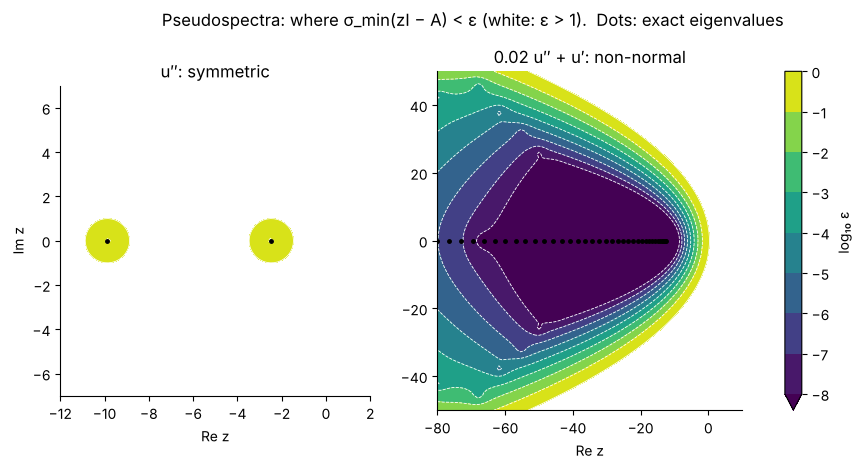

In [20]:
levels = np.arange(-8, 0.5, 1)                                 # ε = 1e-8, 1e-7, ..., 1e-1, 1
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
panels = ((axes[0], re_sym, im_sym, sigma_sym, exact_sym, "u″: symmetric"),
          (axes[1], re_cd, im_cd, sigma_cd, exact_cd, "0.02 u″ + u′: non-normal"))
for ax, re, im, sigma, spectrum, name in panels:
    image = ax.contourf(re, im, np.log10(sigma), levels=levels, cmap="viridis", extend="min")
    ax.contour(re, im, np.log10(sigma), levels=levels, colors="w", linewidths=0.6)
    ax.plot(spectrum, 0 * spectrum, "k.", ms=5)
    ax.set(title=name, xlabel="Re z", xlim=(re[0], re[-1]), ylim=(im[0], im[-1]), aspect="equal")
    ax.grid(False)
axes[0].set_ylabel("Im z")
fig.suptitle("Pseudospectra: where σ_min(zI − A) < ε (white: ε > 1).  Dots: exact eigenvalues", y=1.02)
fig.colorbar(image, ax=axes, label="log₁₀ ε", ticks=levels);

Left: for $u''$ the contours are circles around the eigenvalues. The largest, for
$\varepsilon = 1$, has radius 1, and the one for $\varepsilon = 0.1$ is barely visible. To move
an eigenvalue by 0.1 the operator must be changed by 0.1.

Right: for the convection-diffusion operator (note the larger scale of the axes) the region
for $\varepsilon = 10^{-8}$, the darkest one, already reaches from the real axis to
$\mathrm{Im}\,z = \pm 25$. Every point inside it is an eigenvalue of some operator that differs
from $\mathcal{L}$ in the eighth decimal place. At $z = -30 + 10i$, far from every eigenvalue,
$\sigma_{\min}$ is $10^{-13}$: to rounding error that point is an eigenvalue too. The regions
are bounded by parabolas, and those are the curves that the computed and perturbed eigenvalues
of 8.5 were tracing. In floating-point arithmetic the eigenvalue routine returns the spectrum
of a matrix perturbed by about $10^{-12}$, and that is enough to put its eigenvalues on the
edge of such a region instead of on the real axis. (The small kinks in the contours at the
left are where the unresolved eigenvalues of the $N = 60$ matrix sit.)

**What this means for the physics.** Eigenvalues describe the behaviour as $t \to \infty$. How
long that takes to set in is a different matter. The solution of $u_t = \mathcal{L}u$ is
$u(t) = e^{t\mathcal{L}}u(0)$, and the norm of the matrix exponential measures the largest
possible $\|u(t)\|/\|u(0)\|$.

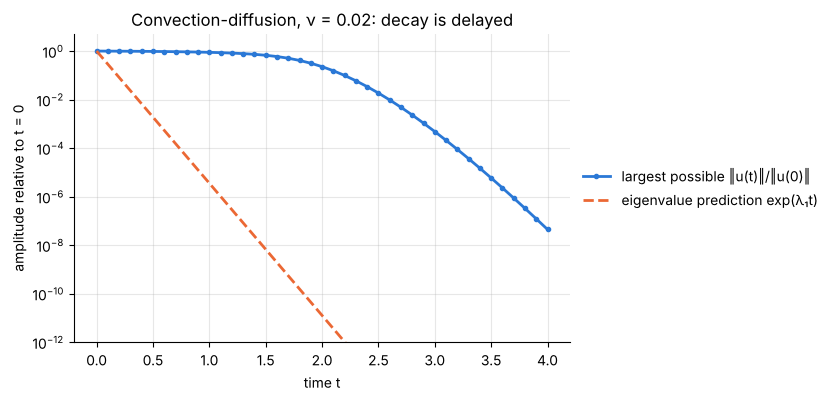

In [21]:
A_weighted = weighted(A_cd, N)
times = np.linspace(0, 4, 41)
actual = np.array([np.linalg.norm(expm(t * A_weighted), 2) for t in times])
from_eigenvalue = np.exp(exact_cd[0] * times)

fig, ax = plt.subplots()
ax.semilogy(times, actual, "o-", ms=3, label="largest possible ‖u(t)‖/‖u(0)‖")
ax.semilogy(times, from_eigenvalue, "--", label="eigenvalue prediction exp(λ₁t)")
ax.set(xlabel="time t", ylabel="amplitude relative to t = 0", ylim=(1e-12, 5),
       title="Convection-diffusion, ν = 0.02: decay is delayed")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [22]:
# Verify: the norm never grows, and its initial decay rate is ν π²/4, not |λ_1|
initial_rate = np.linalg.eigvalsh((A_weighted + A_weighted.T) / 2).max()        # d/dt of log ‖u‖ at t = 0, worst case
late_rate = -np.log(actual[40] / actual[39]) / (times[40] - times[39])
print(f"at t = 1:  actual {actual[10]:.3f}   eigenvalue prediction {from_eigenvalue[10]:.1e}")
print(f"at t = 2:  actual {actual[20]:.3f}   decay rate of the actual norm at t = 4: {late_rate:.1f}")
print(f"initial decay rate {-initial_rate:.4f}   (ν π²/4 = {nu * np.pi**2 / 4:.4f})   eigenvalue rate {-exact_cd[0]:.2f}")
assert np.all(np.diff(actual) < 0) and actual[10] > 0.8 and from_eigenvalue[10] < 1e-5
assert abs(-initial_rate / (nu * np.pi**2 / 4) - 1) < 1e-6

at t = 1:  actual 0.886   eigenvalue prediction 3.5e-06
at t = 2:  actual 0.227   decay rate of the actual norm at t = 4: 10.1
initial decay rate 0.0493   (ν π²/4 = 0.0493)   eigenvalue rate 12.55


The eigenvalue says the solution decays like $e^{-12.55t}$, a factor of 300 000 per unit time.
In fact the largest possible amplitude is still 0.89 at $t = 1$ and 0.23 at $t = 2$. A pulse
released near the right wall is carried along at unit speed, diffusing slowly at the rate
$\nu\pi^2/4 = 0.05$, and is destroyed only when it reaches the left wall two time units later.
After that the decay steepens, but it approaches the eigenvalue rate only gradually: at
$t = 4$ the rate is about 10, against 12.55. An estimate of the time needed to flush the
channel based on $\lambda_1$ would be wrong by a large factor.

In this example the norm can only decrease, because
$\frac{d}{dt}\int u^2\,dx = -2\nu\int u'^2\,dx$. In other non-normal problems it can **grow**
by orders of magnitude before the eventual decay. The classic case is flow in pipes and
channels: the linearized operator has only decaying eigenvalues at Reynolds numbers where the
flow is observed to become turbulent, and its pseudospectra reach far into the unstable half
plane. Small disturbances are amplified transiently until nonlinearity takes over. This is the
mathematics behind subcritical transition (notebook 14 computes the Orr-Sommerfeld spectrum).
The practical message: when an operator is non-normal, eigenvalues give the long-time limit,
and pseudospectra tell you about transients and about sensitivity to small disturbances and
modelling errors.

## Summary

- A differential eigenvalue problem becomes a matrix eigenvalue problem once the boundary
  conditions are imposed on the differentiation matrices.
- Of the eigenvalues of an $N$-point Chebyshev matrix, only about $2N/\pi$ mean anything and about
  $N/2$ are accurate. Always recompute with a larger $N$ and keep what does not move.
- A boundary row without an eigenvalue leads to a generalized problem $A\mathbf{u} = \lambda B\mathbf{u}$
  with singular $B$; discard the infinite eigenvalues. A singular end point needs no condition.
- Unbounded domains can be truncated when the solution decays fast; check both $L$ and $N$.
- For non-normal operators the eigenvalues can be extremely sensitive and say little about
  transients. Pseudospectra, the contours of $\sigma_{\min}(zI - A)$, show both.

## Exercises

1. For the model problem of 8.1, count the leading eigenvalues with relative error below
   $10^{-6}$ for $N = 24, 48, 96$ and $192$. Express each count as a fraction of $N$. Does the
   fraction approach $2/\pi$?
2. The anharmonic oscillator $-u'' + x^4 u = \lambda u$ on the real line has the ground-state
   eigenvalue $\lambda_1 = 1.0603620905$. Reproduce it to nine digits by the truncation method
   of 8.3, and report the values of $L$ and $N$ you needed and how you chose them. Also give
   the next two eigenvalues to eight digits.
3. Longitudinal vibrations of a bar whose cross-section area grows as $A(x) = (1+x)^2$ on
   $0 \le x \le 1$, fixed at both ends, satisfy $(A\,u')' + \mu\,A\,u = 0$ with
   $u(0) = u(1) = 0$. Solve it as a generalized eigenvalue problem with $N = 24$ and give the
   first four values of $\sqrt{\mu}$. Compare them with those of a uniform bar,
   $\sqrt{\mu} = k\pi$, and explain the result with the substitution $v = (1+x)\,u$.
4. A rectangular membrane occupies $-1 \le x \le 1$, $-\tfrac12 \le y \le \tfrac12$ and is fixed
   at the edge. Scale the $y$ derivative, build the Kronecker sum with $N = 20$ in each
   direction and compute the ten lowest eigenvalues. Compare with the exact values
   $-\tfrac{\pi^2}{4}(m^2 + 4n^2)$. Which is the lowest degenerate pair, and why are there fewer
   of them than for the square?
5. For the convection-diffusion operator of 8.5 with $N = 60$, compute $\|e^{t\mathcal{L}}\|$
   in the weighted norm of 8.6 for $\nu = 0.05$, $0.02$ and $0.01$, and find for each the time
   at which it first falls below $10^{-3}$. Compare with the estimate $\ln(1000)/|\lambda_1|$
   from the first eigenvalue. Which simple physical time scale do your results follow instead?